In [33]:
import os, json, pickle

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from xgboost import XGBRegressor
from sklearn.model_selection import GroupKFold
from scipy.signal import find_peaks
from utils.pit.piece_wise_marginal import from_normal

import xarray as xr

from bluemath_tk.core.io import load_model

import cartopy.crs as ccrs
import cartopy.feature as cfeature

os.makedirs("figuras", exist_ok=True)
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

#### Load and Prepare Data

In [34]:
point = 'p102'

#### Predictores: 30 PCs de presión + 10 PCs del gradiente reconstruido (6 h)
pcs_msl = pd.read_csv('outputs/pca/pcs_msl_30_6h.csv', index_col=0, parse_dates=True)
pcs_grad = pd.read_csv('outputs/grad_rec/pcs_grad_rec_6h.csv', index_col=0, parse_dates=True)
data_pcs = pcs_msl.join(pcs_grad)

#### Objetivo: Z (PIT + armónica, 00_PIT), media móvil de 6 h centrada, a 00/06/12/18
waves_df_z = pd.read_csv(f'outputs/marginal/z_bulk_{point}.csv', index_col=0, parse_dates=True)
waves_df_z_6h = waves_df_z.rolling('6h', center=True).mean()
waves_df_z_6h = waves_df_z_6h[waves_df_z_6h.index.hour.isin([0, 6, 12, 18])].dropna()

#### Para volver a metros
pit = pickle.load(open(f'outputs/marginal/transformacion_{point}.pkl', 'rb'))


In [35]:
lags = [0, 6, 12, 18, 24, 30, 36]
X_lagged = pd.concat({f'l{l}': data_pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(data_pcs.index)
X_lagged.columns = [f'{c}_l{l[1:]}' for l, c in X_lagged.columns]
X_lagged = X_lagged.dropna()

idx = X_lagged.index.intersection(waves_df_z_6h.index)
X = X_lagged.loc[idx]
y = waves_df_z_6h.loc[idx, 'VHM0']
print(X.shape)

(60992, 280)


#### XGBoost (profundidad 3)

In [36]:
xgb_params = dict(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=200,
                  subsample=0.8, colsample_bytree=0.8, tree_method='hist', n_jobs=-1, random_state=0)

#### CrossValidation (1985–2015, pliegues por años)

In [37]:
tr = idx < '2016-01-01'
X_tr, y_tr = X[tr], y[tr]

f_oof = pd.Series(np.nan, index=X_tr.index)
for i_fit, i_val in GroupKFold(n_splits=5).split(X_tr, y_tr, groups=X_tr.index.year):
    model = XGBRegressor(**xgb_params).fit(X_tr.iloc[i_fit], y_tr.iloc[i_fit])
    f_oof.iloc[i_val] = model.predict(X_tr.iloc[i_val])

#### Full model

In [38]:
xgb_final = XGBRegressor(**xgb_params).fit(X_tr, y_tr)
f_test = pd.Series(xgb_final.predict(X[~tr]), index=X.index[~tr])

#### Métricas

In [39]:
print(f"6-horaria OOF:  {f_oof.corr(y_tr):.3f}")
print(f"6-horaria test: {f_test.corr(y[~tr]):.3f}")
print(f"diaria OOF:     {f_oof.resample('D').mean().corr(y_tr.resample('D').mean()):.3f}")
print(f"diaria test:    {f_test.resample('D').mean().corr(y[~tr].resample('D').mean()):.3f}")

6-horaria OOF:  0.848
6-horaria test: 0.838
diaria OOF:     0.877
diaria test:    0.866


In [40]:
#### Extremos en test, en metros: pico de f (±24 h) / pico observado en temporales > q99
def hs(z):
    zz = waves_df_z.loc[z.index].copy()
    zz['VHM0'] = z.values
    z0 = pit['harm_z'].inverse_transform(zz)['VHM0'].clip(-6.36, 6.36)
    return pd.Series(pit['marg']['VHM0'].ppf(from_normal(z0).values), index=z.index)

hs_obs, hs_f = hs(y[~tr]), hs(f_test)
picos = hs_obs.index[find_peaks(hs_obs.values, height=hs_obs.quantile(0.99), distance=12)[0]]
ratio = pd.Series([hs_f.loc[t - pd.Timedelta('24h'):t + pd.Timedelta('24h')].max() / hs_obs.loc[t] for t in picos], index=picos)
top10 = hs_obs.loc[picos].nlargest(10).index

print(f"temporales test: {len(picos)} | pico f/obs: {ratio.mean():.2f} | 10 mayores: {ratio.loc[top10].mean():.2f}")
print(f"Juliette: obs {hs_obs.loc['2023-02-25':'2023-03-03'].max():.2f} m | f {hs_f.loc['2023-02-25':'2023-03-03'].max():.2f} m")

temporales test: 53 | pico f/obs: 0.82 | 10 mayores: 0.82
Juliette: obs 5.97 m | f 4.65 m


#### Figuras

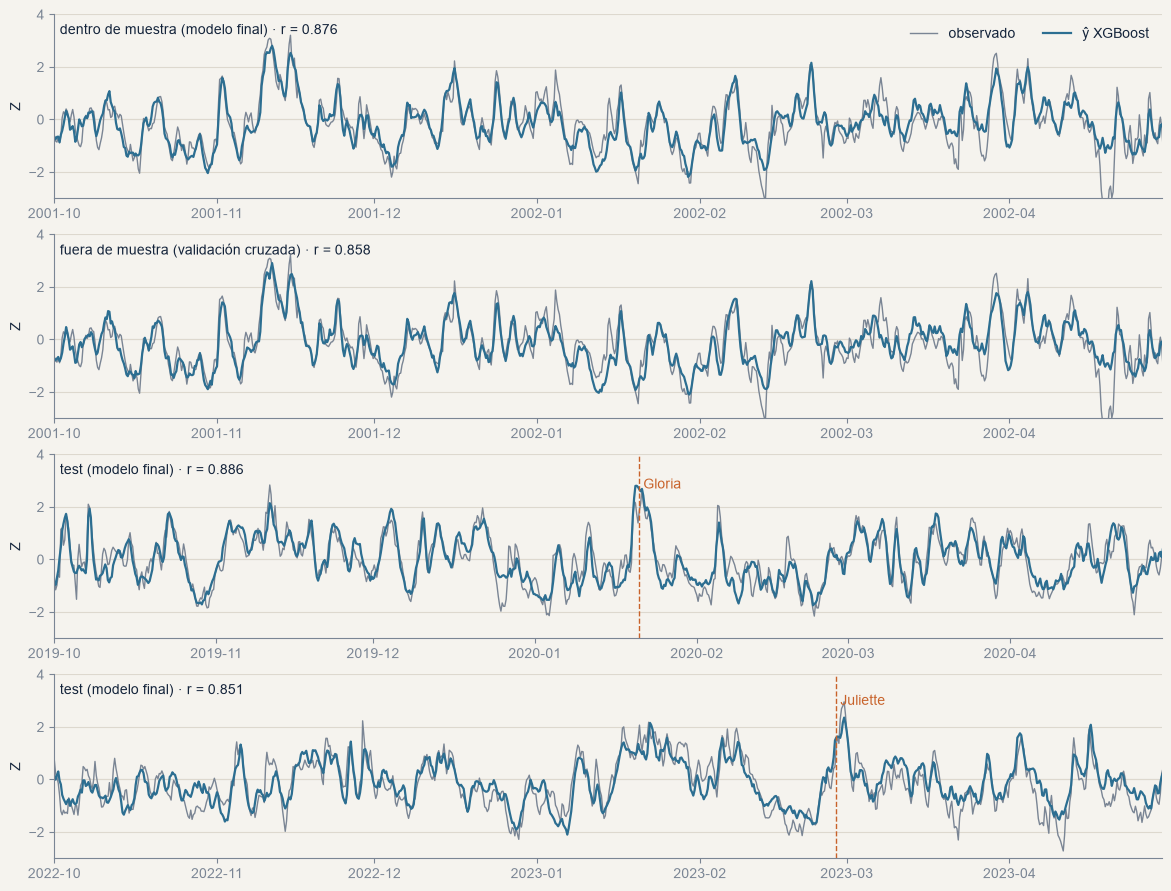

In [41]:
#### Series: dentro de muestra, OOF (validación cruzada) y test (modelo final), con Gloria y Juliette
f_in = pd.Series(xgb_final.predict(X_tr), index=X_tr.index)            # dentro de muestra (1985–2015)

paneles = [
    (f_in,   "2001-10-01", "2002-04-30", "dentro de muestra (modelo final)", None),
    (f_oof,  "2001-10-01", "2002-04-30", "fuera de muestra (validación cruzada)", None),
    (f_test, "2019-10-01", "2020-04-30", "test (modelo final)", ("Gloria", "2020-01-21")),
    (f_test, "2022-10-01", "2023-04-30", "test (modelo final)", ("Juliette", "2023-02-27")),
]

fig, axs = plt.subplots(len(paneles), 1, figsize=(11.6, 2.2 * len(paneles)), constrained_layout=True, facecolor=FONDO)
for ax, (f, t0, t1, titulo, evento) in zip(axs, paneles):
    o, s = y.loc[t0:t1], f.loc[t0:t1]
    ax.plot(o, color=GRIS, lw=1, label="observado")
    ax.plot(s, color=AZUL, lw=1.6, label="ŷ XGBoost")
    ax.axhline(0, color="#DDD8CE", lw=0.8, zorder=0)
    if evento is not None:
        ax.axvline(pd.Timestamp(evento[1]), color=NARANJA, lw=1, ls="--")
        ax.text(pd.Timestamp(evento[1]), ax.get_ylim()[1], f" {evento[0]}", color=NARANJA, fontsize=10, va="top")
    ax.text(0.005, 0.95, f"{titulo} · r = {o.corr(s.reindex(o.index)):.3f}", transform=ax.transAxes,
            fontsize=10, va="top", color=TINTA)
    ax.set(ylabel="Z", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)), ylim=(-3, 4))
    ax.set_facecolor(FONDO)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#DDD8CE", lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=10)
axs[0].legend(frameon=False, loc="upper right", ncol=2, fontsize=10)

fig.savefig("figuras/xgb_series_validacion.png", dpi=200, facecolor=FONDO)
plt.show()

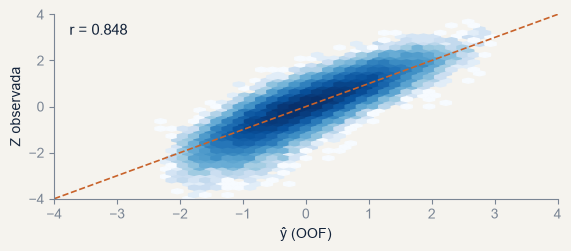

In [42]:
d = pd.concat({"z": y, "f": f_oof}, axis=1).dropna()

fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True, facecolor=FONDO)
hb = ax.hexbin(d["f"], d["z"], gridsize=45, cmap="Blues", mincnt=1, bins="log", extent=(-4, 4, -4, 4))
ax.plot([-4, 4], [-4, 4], color=NARANJA, lw=1.2, ls="--")
ax.text(0.03, 0.95, f"r = {d['z'].corr(d['f']):.3f}", transform=ax.transAxes, va="top", fontsize=11)
ax.set(xlabel="ŷ (OOF)", ylabel="Z observada", xlim=(-4, 4), ylim=(-4, 4))
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=10)

fig.savefig("figuras/xgb_dispersion.png", dpi=200, facecolor=FONDO)
plt.show()

#### Guardar

In [43]:
out_dir = f'outputs/xgb_{point}'
os.makedirs(out_dir, exist_ok=True)

#### Modelo final + orden de columnas que espera
xgb_final.save_model(f'{out_dir}/xgb_final.json')
with open(f'{out_dir}/xgb_features.json', 'w') as f:
    json.dump({'columns': list(X_tr.columns), 'lags_h': lags, 'params': xgb_params,
               'train': ['1985-01-01', '2015-12-31']}, f, indent=1)

#### Serie horaria: z, f y residuo (OOF en 1985–2015, modelo final en 2016–2025)
f_h = pd.concat([f_oof, f_test]).sort_index().resample('h').interpolate()
z_h = waves_df_z['VHM0'].reindex(f_h.index)

residuos = pd.DataFrame({'z': z_h, 'f': f_h, 'r': z_h - f_h})
residuos['periodo'] = np.where(residuos.index < '2016-01-01', 'oof', 'test')
residuos.dropna(subset=['r']).to_csv(f'{out_dir}/residuos_horarios.csv')
print(residuos.dropna().groupby('periodo')['r'].agg(['count', 'std']))

          count       std
periodo                  
oof      271728  0.540621
test      94219  0.545690


In [44]:
#### Temporales (definición oficial: Hs horaria > U99, picos separados 72 h): ¿cuáles pilla la f?
hs_obs_h = pd.read_csv(f'inputs/waves_bulk_{point}.csv', index_col=0, parse_dates=True)['VHM0'].loc['1985':'2025']
U99 = hs_obs_h.quantile(0.99)

f_hh = f_h.loc['1985':'2025'].dropna()
f_hh = f_hh.loc[f_hh.index.intersection(waves_df_z.index)]
hs_f_h = hs(f_hh)

serie = hs_obs_h.asfreq('h')
pk = serie.index[find_peaks(serie.fillna(0).values, height=U99, distance=72)[0]]

temporales = pd.DataFrame({'hs_obs': serie.loc[pk].values,
                           'hs_f': [hs_f_h.loc[t - pd.Timedelta('24h'):t + pd.Timedelta('24h')].max() for t in pk]}, index=pk)
temporales['ratio'] = temporales['hs_f'] / temporales['hs_obs']
temporales['clase'] = pd.cut(temporales['ratio'], [0, 0.5, 0.8, np.inf], labels=['perdido', 'parcial', 'pillado'], right=False)
temporales['periodo'] = np.where(temporales.index < '2016-01-01', 'oof', 'test')
temporales['estacion'] = np.select([temporales.index.month.isin([12, 1, 2]), temporales.index.month.isin([3, 4, 5]),
                                    temporales.index.month.isin([6, 7, 8])], ['invierno', 'primavera', 'verano'], 'otoño')

print(f'U99 = {U99:.2f} m | {len(temporales)} temporales')
display(pd.crosstab(temporales['periodo'], temporales['clase'], margins=True))
display(pd.crosstab(temporales['estacion'], temporales['clase'], margins=True).loc[['invierno', 'primavera', 'verano', 'otoño', 'All']])

temporales.to_csv(f'{out_dir}/temporales_xgb.csv')

U99 = 3.73 m | 255 temporales


clase,perdido,parcial,pillado,All
periodo,,,,
oof,14,104,81,199
test,6,26,24,56
All,20,130,105,255


clase,perdido,parcial,pillado,All
estacion,,,,
invierno,5,65,64,134
primavera,3,31,18,52
verano,2,1,0,3
otoño,10,33,23,66
All,20,130,105,255
